# Fashion SASRec: full and selective LLM augmentation

## Goal
Compare the saved original baseline with **full Qwen, full LLaMA, selective Qwen and selective LLaMA** augmentation. Export per-user scores, audit original sequence preservation and held-out-item overlaps, and compare original-history cohorts (≤7 and >7).

This notebook performs **evaluation only**. Run every cell from the top in Colab with a T4 GPU. Existing analysis outputs are preserved: each execution creates a new dated results folder.

**Validation status:** the earlier baseline/selective evaluations reproduced the supplied training notebooks. This expanded notebook has been checked locally for syntax and its audit/statistical functions tested on controlled fixtures. The full five-checkpoint run must execute in your Colab session; checkpoints and Drive datasets are not available in the authoring environment. Outputs are cleared so old selective-only results cannot be mistaken for new results.

## Context and methods
- NDCG@10 is the primary metric; Hit@10 and MRR@10 are supporting metrics. Recall@10 duplicates Hit@10 with one test target, so is checked but not tested separately.
- Compare the same user's augmented and baseline scores. Delta = augmented minus baseline. Use two-sided paired t-tests and paired-user bootstrap percentile 95% intervals (5,000 resamples).
- **Holm family:** four augmentation conditions × three cohorts × three metrics = **36 planned difference tests**, separately for the all-user exploratory and overlap-excluded sensitivity analyses. Undefined tests retain a conservative p=1 placeholder in the correction family; they are reported as unavailable. These adjusted p-values replace the old selective-only correction and should not be compared as if the families were unchanged.
- Sensitivity exclusions are condition-specific. They remove users with additional validation/test-item occurrences, not the model's prior exposure during training. Do not call these checkpoints contamination-free.
- Full augmentation gives additional interactions to both cohorts. Only selective augmentation has an intentionally unaugmented >7 cohort. Cohorts always use original TOTAL history length, including the two holdouts.
- Training settings differ (in particular selective SASRec batch sizes 128/64 versus baseline 256). Tests compare checkpoint configurations and do not isolate augmentation causally or measure training-seed variability.
- Per-user inference treats users as independent units conditional on these checkpoints and splits. Shared-item dependence and population shift are outside these intervals. A nonsignificant difference does not establish no harm or equivalence.
- Sparse-versus-longer effect contrasts are exploratory Welch tests on user-level deltas. Preserve the four-NDCG-contrast family per population; eight additional Hit/MRR contrasts form a separate supporting family. Optional no-harm/equivalence tests require justified, recorded metric-specific absolute margins and apply only to the selective >7 cohort.
- **Presentation:** Hit@10 is shown alongside NDCG@10 and MRR@10 throughout. Precision@10 = Hit@10 / 10 and Recall@10 = Hit@10 under this verified one-target protocol; their tables inherit Hit statistics and are explicitly marked as derived, not new tests.
- Additional full-versus-selective paired comparisons use a separate exploratory 18-test family per population (two LLMs × three cohorts × three metrics). Sensitivity comparisons exclude the UNION of both conditions' overlap flags. Baseline-versus-augmentation correction remains the original expanded 36-test family.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%pip install -q "recbole==1.2.0" kmeans-pytorch ray

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 13.3 MB/s eta 0:00:00


In [ ]:
import os
import gc
import json
import hashlib
import importlib.metadata as package_metadata
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd
import torch
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

if not hasattr(np, 'float_'):
    np.float_ = np.float64
if not hasattr(np, 'float'):
    np.float = float
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from recbole.quick_start import load_data_and_model
from recbole.utils import get_trainer
from recbole.data.dataloader import FullSortEvalDataLoader

print({p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']})
if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU runtime before evaluation. Do not reinstall PyTorch blindly.')
print('GPU:', torch.cuda.get_device_name(0))
# Test an actual CUDA operation, not just device detection.
print('CUDA calculation:', (torch.ones(2, device='cuda') * 2).cpu().tolist())
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

{'torch': '2.11.0+cu130', 'recbole': '1.2.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3'}
GPU: Tesla T4
CUDA calculation: [2.0, 2.0]


In [ ]:
PROJECT = Path('/content/drive/MyDrive/Wits_Honours_Project')
os.chdir(PROJECT)
THRESHOLD = 7
K = 10
BOOTSTRAP_RESAMPLES = 5000
SEED = 42
NO_HARM_MARGINS = {'hit@10': None, 'ndcg@10': None, 'mrr@10': None}
MARGIN_JUSTIFICATIONS = {'hit@10': '', 'ndcg@10': '', 'mrr@10': ''}

RUNS = {
    'baseline': {'kind': 'baseline', 'checkpoint': 'saved/SASRec-Aug-14-2026_08-12-06.pth',
                 'recorded': {'hit@10': .0188, 'ndcg@10': .0120, 'mrr@10': .0099}},
    'full_qwen': {'kind': 'full', 'checkpoint': 'saved/SASRec-Sep-02-2026_10-16-22.pth',
                  'recorded': {'hit@10': .0201, 'ndcg@10': .0118, 'mrr@10': .0093}},
    'full_llama': {'kind': 'full', 'checkpoint': 'saved/SASRec-Sep-02-2026_10-27-24.pth',
                   'recorded': {'hit@10': .0198, 'ndcg@10': .0123, 'mrr@10': .0100}},
    'selective_qwen': {'kind': 'selective', 'checkpoint': 'saved/sasrec_fashion_selective_qwen/SASRec-Oct-03-2026_06-28-36.pth',
                       'recorded': {'hit@10': .0249, 'ndcg@10': .0137, 'mrr@10': .0104}},
    'selective_llama': {'kind': 'selective', 'checkpoint': 'saved/sasrec_fashion_selective_llama/SASRec-Oct-03-2026_06-32-25.pth',
                        'recorded': {'hit@10': .0217, 'ndcg@10': .0146, 'mrr@10': .0125}},
}
CONDITIONS = [label for label in RUNS if label != 'baseline']
METRICS = ['ndcg@10', 'hit@10', 'mrr@10']
for metric, margin in NO_HARM_MARGINS.items():
    if margin is not None and (not 0 < margin < 1 or not MARGIN_JUSTIFICATIONS[metric].strip()):
        raise ValueError('Supply a justified absolute margin in (0,1) before analysing results.')
missing = [str(PROJECT / r['checkpoint']) for r in RUNS.values() if not (PROJECT / r['checkpoint']).is_file()]
if missing:
    raise FileNotFoundError('Missing checkpoints: ' + '\n'.join(missing))

RUN_DIR = PROJECT / 'results/significance/fashion_sasrec_full_and_selective' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
for subfolder in ['preparation', 'per_user', 'analysis', 'figures']:
    (RUN_DIR / subfolder).mkdir(parents=True, exist_ok=False)
print('New output folder:', RUN_DIR)

New output folder: /content/drive/MyDrive/Wits_Honours_Project/results/significance/fashion_sasrec_full_and_selective/20261014T091423_605138Z


In [ ]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def fingerprint(tokens):
    return hashlib.sha256(json.dumps(sorted(map(str, tokens)), ensure_ascii=False).encode()).hexdigest()

saved_configs = {}
input_paths = {}
provenance = {}
config_rows = []
fields = ['model', 'dataset', 'seed', 'hidden_size', 'inner_size', 'n_layers', 'n_heads',
          'hidden_dropout_prob', 'attn_dropout_prob', 'MAX_ITEM_LIST_LENGTH', 'loss_type',
          'learning_rate', 'train_batch_size', 'epochs', 'stopping_step', 'eval_args', 'topk']
for label, run in RUNS.items():
    checkpoint_path = PROJECT / run['checkpoint']
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    config = checkpoint['config']
    settings = config.final_config_dict if hasattr(config, 'final_config_dict') else config
    saved_configs[label] = {field: settings.get(field) for field in fields}
    if settings['model'] != 'SASRec' or K not in settings['topk']:
        raise ValueError(f'{label}: expected SASRec with saved K={K}.')
    inter_path = Path(settings['data_path']) / f"{settings['dataset']}.inter"
    if not inter_path.is_file():
        raise FileNotFoundError(f'{label}: saved dataset path unavailable: {inter_path}')
    input_paths[label] = inter_path
    provenance[label] = {'checkpoint': str(checkpoint_path), 'checkpoint_sha256': file_hash(checkpoint_path),
                         'inter': str(inter_path), 'inter_sha256': file_hash(inter_path),
                         'config': saved_configs[label], 'saved_epoch': checkpoint.get('epoch')}
    config_rows.append({'condition': label, **{field: settings.get(field) for field in
                        ['dataset', 'hidden_size', 'learning_rate', 'train_batch_size', 'epochs', 'seed']}})
    del checkpoint
display(pd.DataFrame(config_rows))
(RUN_DIR / 'preparation/checkpoint_configs.json').write_text(json.dumps(provenance, indent=2, default=str))

,condition,dataset,hidden_size,learning_rate,train_batch_size,epochs,seed
0,baseline,Fashion,64,0.001,256,100,42
1,full_qwen,Fashion_Qwen,64,0.001,256,100,42
2,full_llama,Fashion_Llama,64,0.001,256,100,42
3,selective_qwen,Fashion_selective_qwen_augmented,64,0.001,128,100,42
4,selective_llama,Fashion_selective_llama_augmented,64,0.001,64,100,42


5739

In [ ]:
def read_inter(path):
    frame = pd.read_csv(path, sep='\t', dtype=str, keep_default_na=False)
    frame.columns = [column.split(':')[0] for column in frame.columns]
    required = ['user_id', 'item_id', 'timestamp']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(f'Invalid .inter schema or empty dataset: {path}')
    if frame[required].eq('').any().any():
        raise ValueError('Empty interaction fields.')
    frame['timestamp'] = pd.to_numeric(frame['timestamp'], errors='raise')
    if not np.isfinite(frame['timestamp']).all():
        raise ValueError('Nonfinite timestamps.')
    if frame.duplicated(['user_id', 'timestamp']).any():
        raise ValueError(f'Timestamp ties require investigating ordering: {path}')
    return frame.sort_values(['user_id', 'timestamp'], kind='stable')

def item_sequences(frame):
    return frame.groupby('user_id')['item_id'].agg(list).to_dict()

def is_subsequence(original, augmented):
    remaining = iter(augmented)
    return all(item in remaining for item in original)

def audit_sequences(original_sequences, augmented_sequences, kind, threshold=7):
    if set(original_sequences) != set(augmented_sequences):
        raise ValueError('User populations differ; this Fashion notebook requires identical users.')
    rows = []
    for user, base in original_sequences.items():
        aug = augmented_sequences[user]
        if len(base) < 3 or base[-2:] != aug[-2:]:
            raise ValueError(f'{user}: invalid original sequence or changed holdout targets.')
        if Counter(base) - Counter(aug) or not is_subsequence(base, aug):
            raise ValueError(f'{user}: original item occurrences/order changed.')
        should_add = 3 if kind == 'full' or len(base) <= threshold else 0
        if len(aug) - len(base) != should_add:
            raise ValueError(f'{user}: augmentation count does not match {kind} policy.')
        if should_add == 0 and aug != base:
            raise ValueError(f'{user}: supposedly unaugmented item sequence changed.')
        added_training = Counter(aug[:-2]) - Counter(base[:-2])
        val_overlap = added_training[base[-2]] > 0
        test_overlap = added_training[base[-1]] > 0
        rows.append({'user_id': user, 'original_length': len(base), 'additional_interactions': should_add,
                     'received_augmentation': should_add > 0, 'validation_overlap': val_overlap,
                     'test_overlap': test_overlap, 'any_overlap': val_overlap or test_overlap,
                     'validation_target': base[-2], 'target_item': base[-1]})
    return pd.DataFrame(rows).set_index('user_id').sort_index()

original_frame = read_inter(input_paths['baseline'])
original_sequences = item_sequences(original_frame)
original_lengths = pd.Series({u: len(items) for u, items in original_sequences.items()}, name='original_length')
original_lengths.index.name = 'user_id'
original_lengths = original_lengths.sort_index()
flags_by_condition = {}
audit_rows = []
original_catalogue = set(original_frame['item_id'])
for label in CONDITIONS:
    augmented_frame = read_inter(input_paths[label])
    if set(augmented_frame['item_id']) != original_catalogue:
        raise ValueError(f'{label}: raw item catalogue differs; use a controlled common-catalogue protocol.')
    flags = audit_sequences(original_sequences, item_sequences(augmented_frame), RUNS[label]['kind'], THRESHOLD)
    flags_by_condition[label] = flags
    flags.reset_index().to_csv(RUN_DIR / f'preparation/{label}_overlap_flags.csv', index=False)
    audit_rows.append({'condition': label, 'kind': RUNS[label]['kind'], 'users': len(flags),
                       'additional_interactions': int(flags.additional_interactions.sum()),
                       'validation_overlap_users': int(flags.validation_overlap.sum()),
                       'test_overlap_users': int(flags.test_overlap.sum()),
                       'any_overlap_users': int(flags.any_overlap.sum()),
                       'overlap_pct': 100 * flags.any_overlap.mean(),
                       'longer_users_augmented': int(((flags.original_length > THRESHOLD) & flags.received_augmentation).sum())})
audits = pd.DataFrame(audit_rows)
display(audits)
audits.to_csv(RUN_DIR / 'preparation/augmentation_audit.csv', index=False)
print('Sparse users:', int((original_lengths <= THRESHOLD).sum()), 'Longer-history users:', int((original_lengths > THRESHOLD).sum()))

,condition,kind,users,additional_interactions,validation_overlap_users,test_overlap_users,any_overlap_users,overlap_pct,longer_users_augmented
0,full_qwen,full,3135,9405,27,16,43,1.371611,641
1,full_llama,full,3135,9405,42,10,52,1.658692,641
2,selective_qwen,selective,3135,7482,23,14,37,1.180223,0
3,selective_llama,selective,3135,7482,35,10,45,1.435407,0


Sparse users: 2494 Longer-history users: 641


### 6. Export scores using native RecBole evaluation
The capture function has local state for each checkpoint, so rerunning it cannot accidentally use another model's ID mapping. It intercepts scores after native padding/history masks. Validation and test targets must match the original chronological split. Native aggregate results and the recorded notebook results must reproduce to the saved precision.

Candidate-exclusion fingerprints are also compared per user in the statistics stage. No prediction contexts are changed and no fit/training call is made.

In [ ]:
def export_checkpoint(label):
    checkpoint_path = PROJECT / RUNS[label]['checkpoint']
    config, model, dataset, train, valid, test = load_data_and_model(str(checkpoint_path))
    if not isinstance(valid, FullSortEvalDataLoader) or not isinstance(test, FullSortEvalDataLoader):
        raise ValueError('Full-sort validation and test are required.')
    if not config['single_spec']:
        raise ValueError('Single-process evaluation is required.')
    trainer = get_trainer(config['MODEL_TYPE'], config['model'])(config, model)
    trainer.eval_collector.data_collect(train)
    native_collect = trainer.eval_collector.eval_batch_collect
    captured = []
    uid, iid = config['USER_ID_FIELD'], config['ITEM_ID_FIELD']

    def capture(scores, interaction, positive_u, positive_i):
        native_collect(scores, interaction, positive_u, positive_i)
        rows = positive_u.detach().cpu().numpy()
        items = positive_i.detach().cpu().numpy()
        if not np.array_equal(np.sort(rows), np.arange(scores.shape[0])):
            raise ValueError('Exactly one held-out item per user is required.')
        if torch.isnan(scores).any() or torch.isposinf(scores).any():
            raise ValueError('Invalid model scores.')
        targets = np.empty(scores.shape[0], dtype=int)
        targets[rows] = items
        users = dataset.id2token(uid, interaction[uid].detach().cpu().numpy())
        target_tokens = dataset.id2token(iid, targets)
        top = torch.topk(scores, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        target_scores = scores[torch.arange(len(targets), device=scores.device), torch.as_tensor(targets, device=scores.device)]
        if not torch.isfinite(target_scores).all():
            raise ValueError('Held-out target is masked/nonfinite.')
        exclusions = torch.isneginf(scores).cpu().numpy()
        for row, user in enumerate(users):
            found = np.flatnonzero(top[row] == targets[row])
            rank = int(found[0] + 1) if len(found) else 0
            captured.append({'user_id': str(user), 'target_item': str(target_tokens[row]), 'top10_rank': rank,
                             'hit@10': int(rank > 0), 'ndcg@10': 1 / np.log2(rank + 1) if rank else 0.,
                             'mrr@10': 1 / rank if rank else 0.,
                             'excluded_items_sha256': fingerprint(dataset.id2token(iid, np.flatnonzero(exclusions[row])))})

    trainer.eval_collector.eval_batch_collect = capture
    try:
        trainer.evaluate(valid, load_best_model=False, show_progress=True)
        val = pd.DataFrame(captured)
        captured.clear()
        native_results = trainer.evaluate(test, load_best_model=False, show_progress=True)
        frame = pd.DataFrame(captured)
    finally:
        trainer.eval_collector.eval_batch_collect = native_collect
    if val.empty or frame.empty or val.user_id.duplicated().any() or frame.user_id.duplicated().any():
        raise ValueError('Empty/repeated evaluation users.')
    frame['validation_target'] = frame.user_id.map(val.set_index('user_id').target_item)
    frame = frame.set_index('user_id').sort_index()
    if set(frame.index) != set(original_sequences) or frame.validation_target.isna().any():
        raise ValueError(f'{label}: filtered evaluation user population differs from original.')
    expected = pd.DataFrame.from_dict({u: {'validation_target': s[-2], 'target_item': s[-1]} for u, s in original_sequences.items()}, orient='index').sort_index()
    for field in ['validation_target', 'target_item']:
        if not np.array_equal(frame[field].to_numpy(), expected[field].to_numpy()):
            raise ValueError(f'{label}: native {field} does not match audited original split.')
    tolerance = 10 ** (-config['metric_decimal_place']) + 1e-9
    checks = []
    for metric in METRICS:
        exported, native = float(frame[metric].mean()), float(native_results[metric])
        recorded = RUNS[label]['recorded'][metric]
        if abs(exported - native) > tolerance or abs(exported - recorded) > tolerance:
            raise ValueError(f'{label}: {metric} failed reproduction: export={exported}, native={native}, recorded={recorded}')
        checks.append({'condition': label, 'metric': metric, 'exported': exported, 'native': native, 'recorded': recorded})
    if abs(float(native_results['recall@10']) - float(frame['hit@10'].mean())) > tolerance:
        raise ValueError('Recall and Hit disagree under one-positive evaluation.')
    output_path = RUN_DIR / f'per_user/{label}.csv'
    frame.reset_index().to_csv(output_path, index=False)
    metadata = {**provenance[label], 'catalogue_sha256': fingerprint(dataset.field2id_token[iid][1:]),
                'eval_args': config['eval_args'], 'topk': config['topk'], 'k': K,
                'native_test_results': {k: float(v) for k, v in native_results.items()}, 'users': len(frame)}
    output_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2, default=str))
    del trainer, model, dataset, train, valid, test
    gc.collect()
    torch.cuda.empty_cache()
    return frame, metadata, checks

score_frames = {}
evaluation_metadata = {}
reproduction_rows = []
for label in RUNS:
    print('\nEvaluating:', label)
    frame, meta, checks = export_checkpoint(label)
    score_frames[label] = frame
    evaluation_metadata[label] = meta
    reproduction_rows.extend(checks)
display(pd.DataFrame(reproduction_rows))
pd.DataFrame(reproduction_rows).to_csv(RUN_DIR / 'analysis/reproduction_checks.csv', index=False)


Evaluating: baseline


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating: full_qwen


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating: full_llama


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating: selective_qwen


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating: selective_llama


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset

,condition,metric,exported,native,recorded
0,baseline,ndcg@10,0.012044,0.0120,0.0120
1,baseline,hit@10,0.018820,0.0188,0.0188
2,baseline,mrr@10,0.009924,0.0099,0.0099
3,full_qwen,ndcg@10,0.011755,0.0118,0.0118
4,full_qwen,hit@10,0.020096,0.0201,0.0201
5,full_qwen,mrr@10,0.009280,0.0093,0.0093
6,full_llama,ndcg@10,0.012298,0.0123,0.0123
7,full_llama,hit@10,0.019777,0.0198,0.0198
8,full_llama,mrr@10,0.010011,0.0100,0.0100
9,selective_qwen,ndcg@10,0.013734,0.0137,0.0137


### 7. Statistical functions
Bootstrap resamples the within-user differences, not users independently between models. Seed each comparison deterministically. Constant differences receive descriptive results and an unavailable paired t-test, rather than a manufactured significance claim. Exact McNemar tests supplement binary Hit@10 in a separate supporting family.

In [ ]:
def bootstrap_interval(differences, seed, repetitions=5000):
    rng = np.random.default_rng(seed)
    means = np.empty(repetitions)
    for start in range(0, repetitions, 128):
        batch = min(128, repetitions - start)
        means[start:start + batch] = rng.choice(differences, size=(batch, len(differences)), replace=True).mean(axis=1)
    return np.quantile(means, [.025, .975])

def comparison_seed(*parts):
    return (SEED + int(hashlib.sha256('|'.join(parts).encode()).hexdigest()[:8], 16)) % (2**32)

def holm_adjust(pvalues):
    values = np.asarray(pvalues, dtype=float)
    order = np.argsort(values)
    adjusted = np.minimum(1., np.maximum.accumulate(values[order] * np.arange(len(values), 0, -1)))
    result = np.empty(len(values))
    result[order] = adjusted
    return result

def paired_summary(b, a, seed, repetitions=5000):
    b, a = np.asarray(b, dtype=float), np.asarray(a, dtype=float)
    if b.shape != a.shape or not np.isfinite(b).all() or not np.isfinite(a).all():
        raise ValueError('Invalid paired scores.')
    d = a - b
    row = {'users': len(d), 'baseline_mean': b.mean() if len(d) else np.nan,
           'augmented_mean': a.mean() if len(d) else np.nan, 'delta': d.mean() if len(d) else np.nan,
           'p_raw': np.nan, 'ci95_low': np.nan, 'ci95_high': np.nan, 'status': 'insufficient_users'}
    if len(d) < 2:
        return row
    low, high = bootstrap_interval(d, seed, repetitions)
    variance = np.std(d, ddof=1)
    row.update({'ci95_low': low, 'ci95_high': high, 'p_raw': float(stats.ttest_rel(a, b).pvalue) if variance > 0 else np.nan,
                'status': 'ok' if variance > 0 else 'zero_variance_no_t_inference',
                'relative_change_pct': 100 * d.mean() / b.mean() if b.mean() else np.nan,
                'improved_pct': 100 * np.mean(d > 0), 'worsened_pct': 100 * np.mean(d < 0),
                'unchanged_pct': 100 * np.mean(d == 0)})
    return row

def adjust_planned_family(frame, raw_column, adjusted_column, group_column):
    frame[adjusted_column] = np.nan
    for group in frame[group_column].unique():
        indices = frame.index[frame[group_column].eq(group)]
        # Keep unavailable planned tests in the family conservatively as p=1.
        raw = frame.loc[indices, raw_column]
        corrected = holm_adjust(raw.fillna(1.).to_numpy())
        frame.loc[indices, adjusted_column] = np.where(raw.notna(), corrected, np.nan)
    return frame

### 8. Baseline comparisons for all four augmentation conditions
This cell verifies candidate catalogues, masks, users and held-out targets before statistical comparisons. It saves individual paired outcomes so every aggregate remains auditable. The two populations use separate correction families, matching the earlier distinction between exploratory and sensitivity results.

In [ ]:
baseline = score_frames['baseline']
results, paired_tables = [], []
for condition in CONDITIONS:
    aug = score_frames[condition]
    flags = flags_by_condition[condition]
    if not baseline.index.equals(aug.index) or not baseline.index.equals(flags.index):
        raise ValueError(f'{condition}: user IDs/order differ.')
    for field in ['target_item', 'validation_target', 'excluded_items_sha256']:
        if not baseline[field].equals(aug[field]):
            raise ValueError(f'{condition}: different {field}; establish a common evaluation task first.')
    for field in ['catalogue_sha256', 'eval_args', 'topk']:
        if evaluation_metadata['baseline'][field] != evaluation_metadata[condition][field]:
            raise ValueError(f'{condition}: different {field}.')
    paired = flags[['original_length', 'received_augmentation', 'any_overlap']].copy()
    paired['condition'] = condition
    paired['augmentation_kind'] = RUNS[condition]['kind']
    for metric in METRICS:
        paired[f'{metric}_baseline'] = baseline[metric]
        paired[f'{metric}_augmented'] = aug[metric]
        paired[f'{metric}_delta'] = aug[metric] - baseline[metric]
    paired_tables.append(paired.reset_index())
    populations = {'all_users_exploratory': np.ones(len(paired), dtype=bool),
                   'overlap_excluded_sensitivity': ~paired.any_overlap.to_numpy()}
    groups = {'all': np.ones(len(paired), dtype=bool), 'sparse': paired.original_length.to_numpy() <= THRESHOLD,
              'longer_history': paired.original_length.to_numpy() > THRESHOLD}
    for population, included in populations.items():
        for group, group_mask in groups.items():
            mask = included & group_mask
            for metric in METRICS:
                b, a = baseline[metric].to_numpy()[mask], aug[metric].to_numpy()[mask]
                row = paired_summary(b, a, comparison_seed(condition, population, group, metric), BOOTSTRAP_RESAMPLES)
                receipt = 'all' if RUNS[condition]['kind'] == 'full' or group == 'sparse' else ('none' if group == 'longer_history' else 'mixed')
                row.update(condition=condition, augmentation_kind=RUNS[condition]['kind'], population=population,
                           group=group, metric=metric, augmentation_receipt=receipt)
                if metric == 'hit@10':
                    gains, losses = int((a > b).sum()), int((a < b).sum())
                    row['mcnemar_p_raw'] = float(stats.binomtest(gains, gains + losses).pvalue) if gains + losses else 1.
                results.append(row)
table = adjust_planned_family(pd.DataFrame(results), 'p_raw', 'p_holm', 'population')
hit_mask = table.metric.eq('hit@10')
hit_tests = adjust_planned_family(table.loc[hit_mask].copy(), 'mcnemar_p_raw', 'mcnemar_p_holm', 'population')
table.loc[hit_tests.index, 'mcnemar_p_holm'] = hit_tests.mcnemar_p_holm
table.to_csv(RUN_DIR / 'analysis/group_results.csv', index=False)
paired_results = pd.concat(paired_tables, ignore_index=True)
paired_results.to_csv(RUN_DIR / 'analysis/paired_user_results.csv', index=False)
ndcg_columns = ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta',
                'relative_change_pct', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\n', metric.upper())
    display(table.loc[table.metric.eq(metric), ndcg_columns].round(6))
print('36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.')


 HIT@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
1,full_qwen,all_users_exploratory,all,3135,0.018820,0.020096,0.001276,6.779661,-0.002552,0.005104,0.527175,1.000000
4,full_qwen,all_users_exploratory,sparse,2494,0.016439,0.020449,0.004010,24.390244,0.000000,0.008420,0.058767,1.000000
7,full_qwen,all_users_exploratory,longer_history,641,0.028081,0.018721,-0.009360,-33.333333,-0.020281,0.001560,0.083264,1.000000
10,full_qwen,overlap_excluded_sensitivity,all,3092,0.018111,0.019082,0.000970,5.357143,-0.002911,0.004851,0.621951,1.000000
13,full_qwen,overlap_excluded_sensitivity,sparse,2457,0.015873,0.019129,0.003256,20.512821,-0.000814,0.007326,0.116684,1.000000
16,full_qwen,overlap_excluded_sensitivity,longer_history,635,0.026772,0.018898,-0.007874,-29.411765,-0.018898,0.001575,0.131779,1.000000
19,full_llama,all_users_exploratory,all,3135,0.018820,0.019777,0.000957,5.084746,-0.002871,0.004785,0.631029,1.000000
22,full_llama,all_users_exploratory,sparse,2494,0.016439,0.018043,0.001604,9.756098,-0.002406,0.005613,0.414325,1.000000
25,full_llama,all_users_exploratory,longer_history,641,0.028081,0.026521,-0.001560,-5.555556,-0.014041,0.010920,0.796481,1.000000
28,full_llama,overlap_excluded_sensitivity,all,3083,0.018488,0.017840,-0.000649,-3.508772,-0.004217,0.002919,0.731661,1.000000



 NDCG@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
0,full_qwen,all_users_exploratory,all,3135,0.012044,0.011755,-0.000289,-2.397695,-0.002368,0.001873,0.794208,1.000000
3,full_qwen,all_users_exploratory,sparse,2494,0.011197,0.012603,0.001406,12.555111,-0.000890,0.003765,0.227856,1.000000
6,full_qwen,all_users_exploratory,longer_history,641,0.015337,0.008455,-0.006882,-44.873350,-0.012998,-0.001521,0.019751,0.592523
9,full_qwen,overlap_excluded_sensitivity,all,3092,0.011587,0.011136,-0.000451,-3.892733,-0.002454,0.001517,0.653058,1.000000
12,full_qwen,overlap_excluded_sensitivity,sparse,2457,0.010987,0.011808,0.000821,7.470958,-0.001238,0.003002,0.447064,1.000000
15,full_qwen,overlap_excluded_sensitivity,longer_history,635,0.013907,0.008534,-0.005372,-38.630782,-0.010404,-0.000701,0.033860,1.000000
18,full_llama,all_users_exploratory,all,3135,0.012044,0.012298,0.000255,2.115406,-0.001906,0.002377,0.817559,1.000000
21,full_llama,all_users_exploratory,sparse,2494,0.011197,0.012082,0.000885,7.903884,-0.001246,0.003137,0.422641,1.000000
24,full_llama,all_users_exploratory,longer_history,641,0.015337,0.013139,-0.002197,-14.327620,-0.008785,0.004114,0.502741,1.000000
27,full_llama,overlap_excluded_sensitivity,all,3083,0.011760,0.011474,-0.000286,-2.435756,-0.002307,0.001711,0.778883,1.000000



 MRR@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
2,full_qwen,all_users_exploratory,all,3135,0.009924,0.009280,-0.000644,-6.488603,-0.002572,0.001256,0.505230,1.000000
5,full_qwen,all_users_exploratory,sparse,2494,0.009584,0.010273,0.000689,7.191951,-0.001353,0.002735,0.506625,1.000000
8,full_qwen,all_users_exploratory,longer_history,641,0.011245,0.005414,-0.005831,-51.852464,-0.011042,-0.001614,0.017469,0.541551
11,full_qwen,overlap_excluded_sensitivity,all,3092,0.009550,0.008784,-0.000766,-8.021879,-0.002433,0.000855,0.367387,1.000000
14,full_qwen,overlap_excluded_sensitivity,sparse,2457,0.009491,0.009641,0.000150,1.582602,-0.001683,0.001991,0.874138,1.000000
17,full_qwen,overlap_excluded_sensitivity,longer_history,635,0.009777,0.005466,-0.004311,-44.097156,-0.008355,-0.000858,0.024230,0.755355
20,full_llama,all_users_exploratory,all,3135,0.009924,0.010011,0.000087,0.878838,-0.001652,0.001935,0.925676,1.000000
23,full_llama,all_users_exploratory,sparse,2494,0.009584,0.010257,0.000673,7.024272,-0.001140,0.002623,0.476723,1.000000
26,full_llama,all_users_exploratory,longer_history,641,0.011245,0.009053,-0.002193,-19.499037,-0.007510,0.003151,0.419180,1.000000
29,full_llama,overlap_excluded_sensitivity,all,3083,0.009659,0.009512,-0.000147,-1.520543,-0.001762,0.001501,0.860301,1.000000


36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.


### 9. Does the effect differ between sparse and longer-history users?
Use Welch tests on user-level Hit, NDCG and MRR changes across the two disjoint cohorts. A significant result in one cohort and a nonsignificant result in the other would not, by itself, establish an effect difference. The original four-condition NDCG correction family is preserved per population; the eight additional Hit/MRR contrasts form a separate supporting family per population.

In [ ]:
contrast_rows = []
for condition in CONDITIONS:
    p = paired_results[paired_results.condition.eq(condition)]
    for population in ['all_users_exploratory', 'overlap_excluded_sensitivity']:
        selected = p if population == 'all_users_exploratory' else p.loc[~p.any_overlap]
        for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
            sparse = selected.loc[selected.original_length <= THRESHOLD, f'{metric}_delta'].to_numpy()
            longer = selected.loc[selected.original_length > THRESHOLD, f'{metric}_delta'].to_numpy()
            valid = len(sparse) >= 2 and len(longer) >= 2
            variable = valid and (np.std(sparse, ddof=1) > 0 or np.std(longer, ddof=1) > 0)
            # Preserve the original four-NDCG-test family; add eight supporting
            # Hit/MRR contrasts per population, explicitly labelled separately.
            family = 'ndcg_contrasts' if metric == 'ndcg@10' else 'hit_mrr_supporting_contrasts'
            contrast_rows.append({'condition': condition, 'population': population, 'metric': metric,
                                  'correction_family': family + '_' + population,
                                  'sparse_users': len(sparse), 'longer_users': len(longer),
                                  'sparse_minus_longer_delta': sparse.mean() - longer.mean() if len(sparse) and len(longer) else np.nan,
                                  'p_raw': float(stats.ttest_ind(sparse, longer, equal_var=False).pvalue) if variable else np.nan})
contrasts = adjust_planned_family(pd.DataFrame(contrast_rows), 'p_raw', 'p_holm', 'correction_family')
contrasts.to_csv(RUN_DIR / 'analysis/cohort_effect_contrasts.csv', index=False)
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\nSparse versus longer-history effect:', metric)
    display(contrasts.loc[contrasts.metric.eq(metric)].round(6))



Sparse versus longer-history effect: hit@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
0,full_qwen,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.013370,0.021342,0.109551
3,full_qwen,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2457,635,0.011130,0.047786,0.238930
6,full_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.003164,0.618866,1.000000
9,full_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2449,634,0.003155,0.609945,1.000000
12,selective_qwen,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.005657,0.282713,1.000000
15,selective_qwen,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2457,641,0.004952,0.342786,1.000000
18,selective_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.017336,0.007725,0.061802
21,selective_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2449,641,0.016229,0.012328,0.098624



Sparse versus longer-history effect: ndcg@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
1,full_qwen,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,2494,641,0.008288,0.009033,0.031329
4,full_qwen,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,2457,635,0.006193,0.024433,0.073300
7,full_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,2494,641,0.003082,0.372961,0.443139
10,full_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,2449,634,0.001932,0.548741,0.548741
13,selective_qwen,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,2494,641,0.003387,0.221569,0.443139
16,selective_qwen,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,2457,641,0.003060,0.265453,0.530905
19,selective_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,2494,641,0.010609,0.007832,0.031329
22,selective_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,2449,641,0.009885,0.012757,0.051030



Sparse versus longer-history effect: mrr@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
2,full_qwen,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.006520,0.014357,0.100496
5,full_qwen,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2457,635,0.004462,0.036564,0.219386
8,full_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.002866,0.318761,1.000000
11,full_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2449,634,0.001365,0.583736,1.000000
14,selective_qwen,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.002624,0.277810,1.000000
17,selective_qwen,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2457,641,0.002411,0.316355,1.000000
20,selective_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,2494,641,0.008300,0.018259,0.109551
23,selective_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,2449,641,0.007697,0.027746,0.194225


### 10. Optional no-harm/equivalence tests for selective unaugmented users
These run only for metrics with justified margins entered before examining this analysis. For each chosen metric, non-inferiority tests whether delta is greater than −margin; TOST equivalence tests whether it lies inside (−margin,+margin). Holm correction covers both selective conditions and all metrics with a chosen margin, separately for each test type. Margins are absolute rate/score units; Hit 0.01 means one percentage point. The group has no flagged users under the verified selective policy, so repeating it as a sensitivity test would be redundant. Full augmentation has no deliberately unaugmented >7 group.

In [ ]:
margin_rows = []
chosen_margins = {metric: margin for metric, margin in NO_HARM_MARGINS.items() if margin is not None}
if not chosen_margins:
    print('No justified margins chosen: no claim of no meaningful harm or equivalence is tested.')
else:
    for metric, margin in chosen_margins.items():
        for condition in ['selective_qwen', 'selective_llama']:
            p = paired_results.loc[paired_results.condition.eq(condition) & (paired_results.original_length > THRESHOLD)]
            d = p[f'{metric}_delta'].to_numpy()
            n, mean = len(d), d.mean() if len(d) else np.nan
            se = np.std(d, ddof=1) / np.sqrt(n) if n >= 2 else 0.
            lower_p = float(stats.t.sf((mean + margin) / se, n - 1)) if se > 0 else np.nan
            upper_p = float(stats.t.cdf((mean - margin) / se, n - 1)) if se > 0 else np.nan
            margin_rows.append({'condition': condition, 'metric': metric, 'users': n, 'delta': mean, 'margin': margin,
                                'noninferiority_p_raw': lower_p,
                                'equivalence_p_raw': max(lower_p, upper_p) if se > 0 else np.nan})
    margin_table = pd.DataFrame(margin_rows)
    for kind in ['noninferiority', 'equivalence']:
        raw = margin_table[f'{kind}_p_raw']
        margin_table[f'{kind}_p_holm'] = np.where(raw.notna(), holm_adjust(raw.fillna(1.)), np.nan)
    margin_table.to_csv(RUN_DIR / 'analysis/optional_margin_tests.csv', index=False)
    display(margin_table.round(6))


No justified margins chosen: no claim of no meaningful harm or equivalence is tested.


## Results: baseline, full augmentation and selective augmentation
### 11. Absolute performance and all tested metrics
The overview gives the original baseline its own rows alongside all four augmentation conditions. The overview uses all original test users: no condition-specific exclusions. It reports Hit@10, NDCG@10 and MRR@10, with derived Recall@10 and Precision@10 for completeness. Precision is a fraction of the ten recommendations, not a hit rate.

The separate comparison table includes matched baseline scores within each sensitivity population; those baseline averages can differ by condition because different users were excluded. Raw and adjusted p-values, pointwise intervals, relative changes and sample sizes are retained in the CSVs. Values remain fractions (e.g. Hit 0.0249 = 2.49%); relative changes are percentages.

In [ ]:
DISPLAY_METRICS = ['hit@10', 'ndcg@10', 'mrr@10']
GROUPS = ['all', 'sparse', 'longer_history']
LABELS = {'baseline': 'Original baseline', 'full_qwen': 'Full Qwen', 'full_llama': 'Full LLaMA',
          'selective_qwen': 'Selective Qwen', 'selective_llama': 'Selective LLaMA'}
GROUP_TITLES = {'all': 'All users', 'sparse': 'Original history ≤7', 'longer_history': 'Original history >7'}
METRIC_TITLES = {'hit@10': 'Hit rate @10', 'ndcg@10': 'NDCG@10', 'mrr@10': 'MRR@10'}
POPULATIONS = ['all_users_exploratory', 'overlap_excluded_sensitivity']

overview_rows = []
for condition, scores in score_frames.items():
    lengths = original_lengths.reindex(scores.index)
    for group in GROUPS:
        mask = np.ones(len(scores), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
        selected = scores.loc[mask]
        overview_rows.append({'condition': condition, 'group': group, 'users': len(selected),
                              'test_hits': int(selected['hit@10'].sum()),
                              **{metric: selected[metric].mean() for metric in DISPLAY_METRICS},
                              'recall@10': selected['hit@10'].mean(),
                              'precision@10': selected['hit@10'].mean() / K})
overview = pd.DataFrame(overview_rows)
overview.to_csv(RUN_DIR / 'analysis/absolute_performance.csv', index=False)
display(overview.round(6))

# No new tests: Recall and Precision are rescaled Hit information here.
derived = []
for name, scale in [('recall@10', 1.), ('precision@10', 1. / K)]:
    frame = table.loc[table.metric.eq('hit@10')].copy()
    frame['metric'] = name
    for column in ['baseline_mean', 'augmented_mean', 'delta', 'ci95_low', 'ci95_high']:
        frame[column] *= scale
    frame['derived_from'] = 'hit@10'
    frame['test_note'] = 'Inherited Hit@10 test; no independent hypothesis added'
    derived.append(frame)
all_metric_results = pd.concat([table.assign(derived_from='', test_note='Tested metric'), *derived], ignore_index=True)
all_metric_results.to_csv(RUN_DIR / 'analysis/all_metrics_including_derived.csv', index=False)
display(all_metric_results.loc[all_metric_results.metric.eq('precision@10'),
        ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta', 'p_holm', 'test_note']].round(6))

,condition,group,users,test_hits,hit@10,ndcg@10,mrr@10,recall@10,precision@10
0,baseline,all,3135,59,0.018820,0.012044,0.009924,0.018820,0.001882
1,baseline,sparse,2494,41,0.016439,0.011197,0.009584,0.016439,0.001644
2,baseline,longer_history,641,18,0.028081,0.015337,0.011245,0.028081,0.002808
3,full_qwen,all,3135,63,0.020096,0.011755,0.009280,0.020096,0.002010
4,full_qwen,sparse,2494,51,0.020449,0.012603,0.010273,0.020449,0.002045
5,full_qwen,longer_history,641,12,0.018721,0.008455,0.005414,0.018721,0.001872
6,full_llama,all,3135,62,0.019777,0.012298,0.010011,0.019777,0.001978
7,full_llama,sparse,2494,45,0.018043,0.012082,0.010257,0.018043,0.001804
8,full_llama,longer_history,641,17,0.026521,0.013139,0.009053,0.026521,0.002652
9,selective_qwen,all,3135,78,0.024880,0.013734,0.010368,0.024880,0.002488


,condition,population,group,users,baseline_mean,augmented_mean,delta,p_holm,test_note
96,full_qwen,all_users_exploratory,all,3135,0.001882,0.002010,0.000128,1.000000,Inherited Hit@10 test; no independent hypothes...
97,full_qwen,all_users_exploratory,sparse,2494,0.001644,0.002045,0.000401,1.000000,Inherited Hit@10 test; no independent hypothes...
98,full_qwen,all_users_exploratory,longer_history,641,0.002808,0.001872,-0.000936,1.000000,Inherited Hit@10 test; no independent hypothes...
99,full_qwen,overlap_excluded_sensitivity,all,3092,0.001811,0.001908,0.000097,1.000000,Inherited Hit@10 test; no independent hypothes...
100,full_qwen,overlap_excluded_sensitivity,sparse,2457,0.001587,0.001913,0.000326,1.000000,Inherited Hit@10 test; no independent hypothes...
101,full_qwen,overlap_excluded_sensitivity,longer_history,635,0.002677,0.001890,-0.000787,1.000000,Inherited Hit@10 test; no independent hypothes...
102,full_llama,all_users_exploratory,all,3135,0.001882,0.001978,0.000096,1.000000,Inherited Hit@10 test; no independent hypothes...
103,full_llama,all_users_exploratory,sparse,2494,0.001644,0.001804,0.000160,1.000000,Inherited Hit@10 test; no independent hypothes...
104,full_llama,all_users_exploratory,longer_history,641,0.002808,0.002652,-0.000156,1.000000,Inherited Hit@10 test; no independent hypothes...
105,full_llama,overlap_excluded_sensitivity,all,3083,0.001849,0.001784,-0.000065,1.000000,Inherited Hit@10 test; no independent hypothes...


### 12. Which users gain or lose a hit?
Count users who gain a top-10 hit, lose a hit, retain a hit or remain misses. These four categories reconcile to the group's sample size. For users who hit under both models, also count rank improvements/deteriorations via NDCG; MRR and NDCG have the same direction of rank change with one target. Report counts rather than unstable percentages conditional on a tiny number of retained hits.

Exact McNemar tests focus on gained versus lost hits. Their supporting Holm family is 12 planned Hit comparisons per population, separate from the 36 paired-t comparisons. Do not select whichever test produces the smaller p-value; report them as complementary assessments.

In [ ]:
transition_rows = []
for condition in CONDITIONS:
    pairs = paired_results.loc[paired_results.condition.eq(condition)]
    for population in POPULATIONS:
        eligible = pairs if population == 'all_users_exploratory' else pairs.loc[~pairs.any_overlap]
        for group in GROUPS:
            selected = eligible if group == 'all' else eligible.loc[eligible.original_length <= THRESHOLD if group == 'sparse' else eligible.original_length > THRESHOLD]
            b, a = selected['hit@10_baseline'], selected['hit@10_augmented']
            both = b.eq(1) & a.eq(1)
            row = {'condition': condition, 'population': population, 'group': group, 'users': len(selected),
                   'baseline_hits': int(b.sum()), 'augmented_hits': int(a.sum()),
                   'gained_hit_users': int((b.eq(0) & a.eq(1)).sum()),
                   'lost_hit_users': int((b.eq(1) & a.eq(0)).sum()),
                   'retained_hit_users': int(both.sum()), 'remained_miss_users': int((b.eq(0) & a.eq(0)).sum()),
                   'better_rank_retained_hits': int((both & selected['ndcg@10_delta'].gt(0)).sum()),
                   'worse_rank_retained_hits': int((both & selected['ndcg@10_delta'].lt(0)).sum()),
                   'same_rank_retained_hits': int((both & selected['ndcg@10_delta'].eq(0)).sum())}
            assert row['gained_hit_users'] + row['lost_hit_users'] + row['retained_hit_users'] + row['remained_miss_users'] == row['users']
            assert row['augmented_hits'] - row['baseline_hits'] == row['gained_hit_users'] - row['lost_hit_users']
            row['gained_hit_pct'] = 100 * row['gained_hit_users'] / row['users'] if row['users'] else np.nan
            row['lost_hit_pct'] = 100 * row['lost_hit_users'] / row['users'] if row['users'] else np.nan
            transition_rows.append(row)
transitions = pd.DataFrame(transition_rows)
hit_tests = table.loc[table.metric.eq('hit@10'), ['condition', 'population', 'group', 'mcnemar_p_raw', 'mcnemar_p_holm']]
transitions = transitions.merge(hit_tests, on=['condition', 'population', 'group'], validate='one_to_one')
transitions.to_csv(RUN_DIR / 'analysis/hit_transitions.csv', index=False)
display(transitions.round(6))

# Individual rank-based outcomes for both ranking metrics remain available too.
outcome_columns = ['condition', 'population', 'group', 'metric', 'users', 'improved_pct', 'worsened_pct', 'unchanged_pct']
table[outcome_columns].to_csv(RUN_DIR / 'analysis/user_outcome_percentages.csv', index=False)

,condition,population,group,users,baseline_hits,augmented_hits,gained_hit_users,lost_hit_users,retained_hit_users,remained_miss_users,better_rank_retained_hits,worse_rank_retained_hits,same_rank_retained_hits,gained_hit_pct,lost_hit_pct,mcnemar_p_raw,mcnemar_p_holm
0,full_qwen,all_users_exploratory,all,3135,59,63,22,18,41,3054,8,13,20,0.701754,0.574163,0.635828,1.000000
1,full_qwen,all_users_exploratory,sparse,2494,41,51,19,9,32,2434,5,9,18,0.761828,0.360866,0.087159,0.784427
2,full_qwen,all_users_exploratory,longer_history,641,18,12,3,9,9,620,3,4,2,0.468019,1.404056,0.145996,1.000000
3,full_qwen,overlap_excluded_sensitivity,all,3092,56,59,20,17,39,3016,8,12,19,0.646831,0.549806,0.742829,1.000000
4,full_qwen,overlap_excluded_sensitivity,sparse,2457,39,47,17,9,30,2401,5,8,17,0.691901,0.366300,0.168638,1.000000
5,full_qwen,overlap_excluded_sensitivity,longer_history,635,17,12,3,8,9,615,3,4,2,0.472441,1.259843,0.226562,1.000000
6,full_llama,all_users_exploratory,all,3135,59,62,21,18,41,3055,9,13,19,0.669856,0.574163,0.749259,1.000000
7,full_llama,all_users_exploratory,sparse,2494,41,45,14,10,31,2439,5,8,18,0.561347,0.400962,0.541256,1.000000
8,full_llama,all_users_exploratory,longer_history,641,18,17,7,8,10,616,4,5,1,1.092044,1.248050,1.000000,1.000000
9,full_llama,overlap_excluded_sensitivity,all,3083,57,55,16,18,39,3010,9,11,19,0.518975,0.583847,0.864166,1.000000


### 13. Full versus selective augmentation directly
Compare the same users under selective and full augmentation for each LLM. Delta here = **selective minus full**, not augmented minus baseline. This directly assesses the two existing augmentation configurations; differences in training settings and overlap exposure still limit causal interpretation. Sensitivity exclusions use the union of flags from both compared conditions, so the pairing uses identical users.

In [ ]:
policy_rows = []
for llm in ['qwen', 'llama']:
    full_name, selective_name = f'full_{llm}', f'selective_{llm}'
    full, selective = score_frames[full_name], score_frames[selective_name]
    if not full.index.equals(selective.index):
        raise ValueError('Policy comparison requires identical ordered users.')
    union_overlap = (flags_by_condition[full_name].any_overlap | flags_by_condition[selective_name].any_overlap).reindex(full.index)
    lengths = original_lengths.reindex(full.index)
    for population in POPULATIONS:
        included = np.ones(len(full), dtype=bool) if population == 'all_users_exploratory' else ~union_overlap.to_numpy()
        for group in GROUPS:
            group_mask = np.ones(len(full), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
            mask = included & group_mask
            for metric in DISPLAY_METRICS:
                row = paired_summary(full[metric].to_numpy()[mask], selective[metric].to_numpy()[mask],
                                     comparison_seed('policy', llm, population, group, metric), BOOTSTRAP_RESAMPLES)
                row['full_mean'] = row.pop('baseline_mean')
                row['selective_mean'] = row.pop('augmented_mean')
                row.update(llm=llm, population=population, group=group, metric=metric, comparison='selective_minus_full')
                policy_rows.append(row)
policy_results = adjust_planned_family(pd.DataFrame(policy_rows), 'p_raw', 'p_holm', 'population')
policy_results.to_csv(RUN_DIR / 'analysis/full_vs_selective.csv', index=False)
for metric in DISPLAY_METRICS:
    print('\nFull versus selective:', METRIC_TITLES[metric])
    display(policy_results.loc[policy_results.metric.eq(metric),
            ['llm', 'population', 'group', 'users', 'full_mean', 'selective_mean', 'delta', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']].round(6))


Full versus selective: Hit rate @10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
0,qwen,all_users_exploratory,all,3135,0.020096,0.024880,0.004785,0.000000,0.009569,0.046928,0.563137
3,qwen,all_users_exploratory,sparse,2494,0.020449,0.023657,0.003208,-0.001604,0.008019,0.205967,1.000000
6,qwen,all_users_exploratory,longer_history,641,0.018721,0.029641,0.010920,-0.001560,0.023401,0.089569,0.806125
9,qwen,overlap_excluded_sensitivity,all,3092,0.019082,0.023609,0.004528,0.000000,0.009379,0.056747,0.567468
12,qwen,overlap_excluded_sensitivity,sparse,2457,0.019129,0.022385,0.003256,-0.001628,0.008140,0.194426,1.000000
15,qwen,overlap_excluded_sensitivity,longer_history,635,0.018898,0.028346,0.009449,-0.003150,0.022047,0.133729,1.000000
18,llama,all_users_exploratory,all,3135,0.019777,0.021691,0.001914,-0.002233,0.006061,0.376429,1.000000
21,llama,all_users_exploratory,sparse,2494,0.018043,0.022855,0.004812,0.000401,0.009222,0.028431,0.426466
24,llama,all_users_exploratory,longer_history,641,0.026521,0.017161,-0.009360,-0.021841,0.003120,0.133728,1.000000
27,llama,overlap_excluded_sensitivity,all,3083,0.017840,0.020759,0.002919,-0.001297,0.007136,0.169950,1.000000



Full versus selective: NDCG@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
1,qwen,all_users_exploratory,all,3135,0.011755,0.013734,0.001979,-0.000036,0.004044,0.058843,0.647269
4,qwen,all_users_exploratory,sparse,2494,0.012603,0.013580,0.000977,-0.001205,0.003154,0.380225,1.000000
7,qwen,all_users_exploratory,longer_history,641,0.008455,0.014333,0.005879,0.000767,0.011423,0.031564,0.441891
10,qwen,overlap_excluded_sensitivity,all,3092,0.011136,0.013229,0.002093,0.000106,0.004092,0.042832,0.556812
13,qwen,overlap_excluded_sensitivity,sparse,2457,0.011808,0.013044,0.001236,-0.000932,0.003347,0.259359,1.000000
16,qwen,overlap_excluded_sensitivity,longer_history,635,0.008534,0.013944,0.005409,0.000349,0.010921,0.045977,0.556812
19,llama,all_users_exploratory,all,3135,0.012298,0.014612,0.002313,-0.000229,0.004904,0.076317,0.763171
22,llama,all_users_exploratory,sparse,2494,0.012082,0.015934,0.003852,0.001338,0.006520,0.003978,0.067623
25,llama,all_users_exploratory,longer_history,641,0.013139,0.009465,-0.003674,-0.010710,0.003668,0.319989,1.000000
28,llama,overlap_excluded_sensitivity,all,3083,0.011474,0.014051,0.002578,0.000051,0.005176,0.048935,0.556812



Full versus selective: MRR@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
2,qwen,all_users_exploratory,all,3135,0.009280,0.010368,0.001089,-0.000412,0.002684,0.169104,1.000000
5,qwen,all_users_exploratory,sparse,2494,0.010273,0.010565,0.000292,-0.001386,0.001986,0.740418,1.000000
8,qwen,all_users_exploratory,longer_history,641,0.005414,0.009602,0.004188,0.000802,0.008053,0.019814,0.317020
11,qwen,overlap_excluded_sensitivity,all,3092,0.008784,0.010097,0.001313,-0.000214,0.002832,0.087188,0.784695
14,qwen,overlap_excluded_sensitivity,sparse,2457,0.009641,0.010259,0.000618,-0.001062,0.002304,0.465380,1.000000
17,qwen,overlap_excluded_sensitivity,longer_history,635,0.005466,0.009468,0.004003,0.000744,0.007667,0.026244,0.393658
20,llama,all_users_exploratory,all,3135,0.010011,0.012452,0.002441,0.000277,0.004843,0.036465,0.474043
23,llama,all_users_exploratory,sparse,2494,0.010257,0.013810,0.003552,0.001256,0.006124,0.003571,0.064274
26,llama,all_users_exploratory,longer_history,641,0.009053,0.007171,-0.001881,-0.008059,0.004504,0.553638,1.000000
29,llama,overlap_excluded_sensitivity,all,3083,0.009512,0.012014,0.002502,0.000304,0.004895,0.033727,0.472183


### 14. Performance and uncertainty plots for Hit, NDCG and MRR
For each tested metric, show both populations and all three cohorts. Change plots include the original baseline at zero as a reference, **not an estimated confidence interval**. Absolute-score plots show the baseline as its own row for all-user results. Sensitivity panels show each condition's matching baseline because exclusions differ. Absolute score points have no confidence intervals; uncertainty is supplied in the paired-change panels.

Hit rate axes show percentages. Hit changes are percentage points; NDCG and MRR use raw score units. Use adjusted p-values in tables for inference. All change intervals are pointwise and do not incorporate multiple-test corrections.

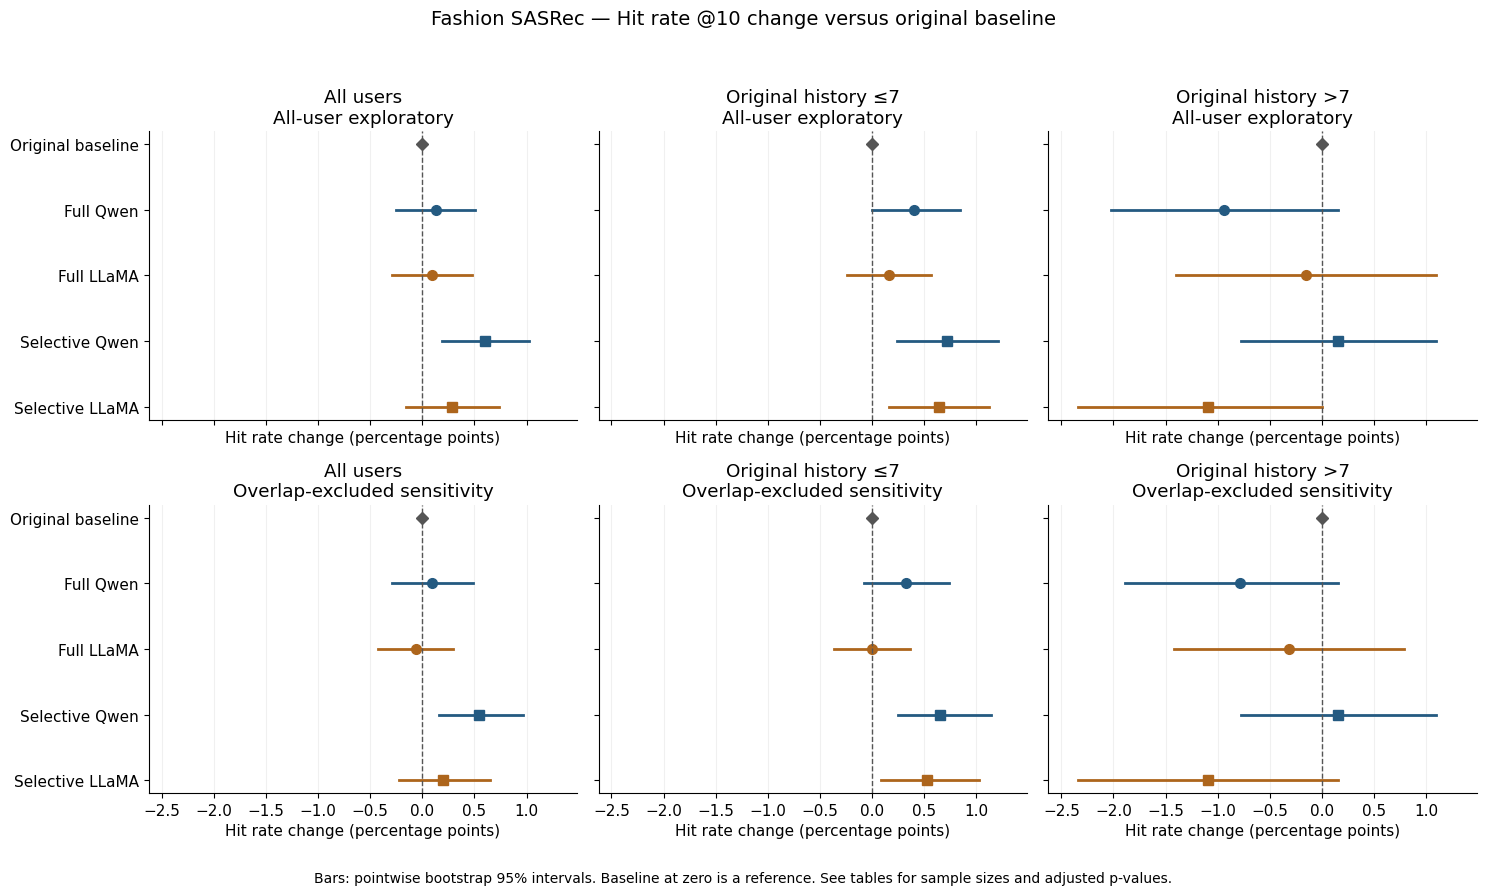

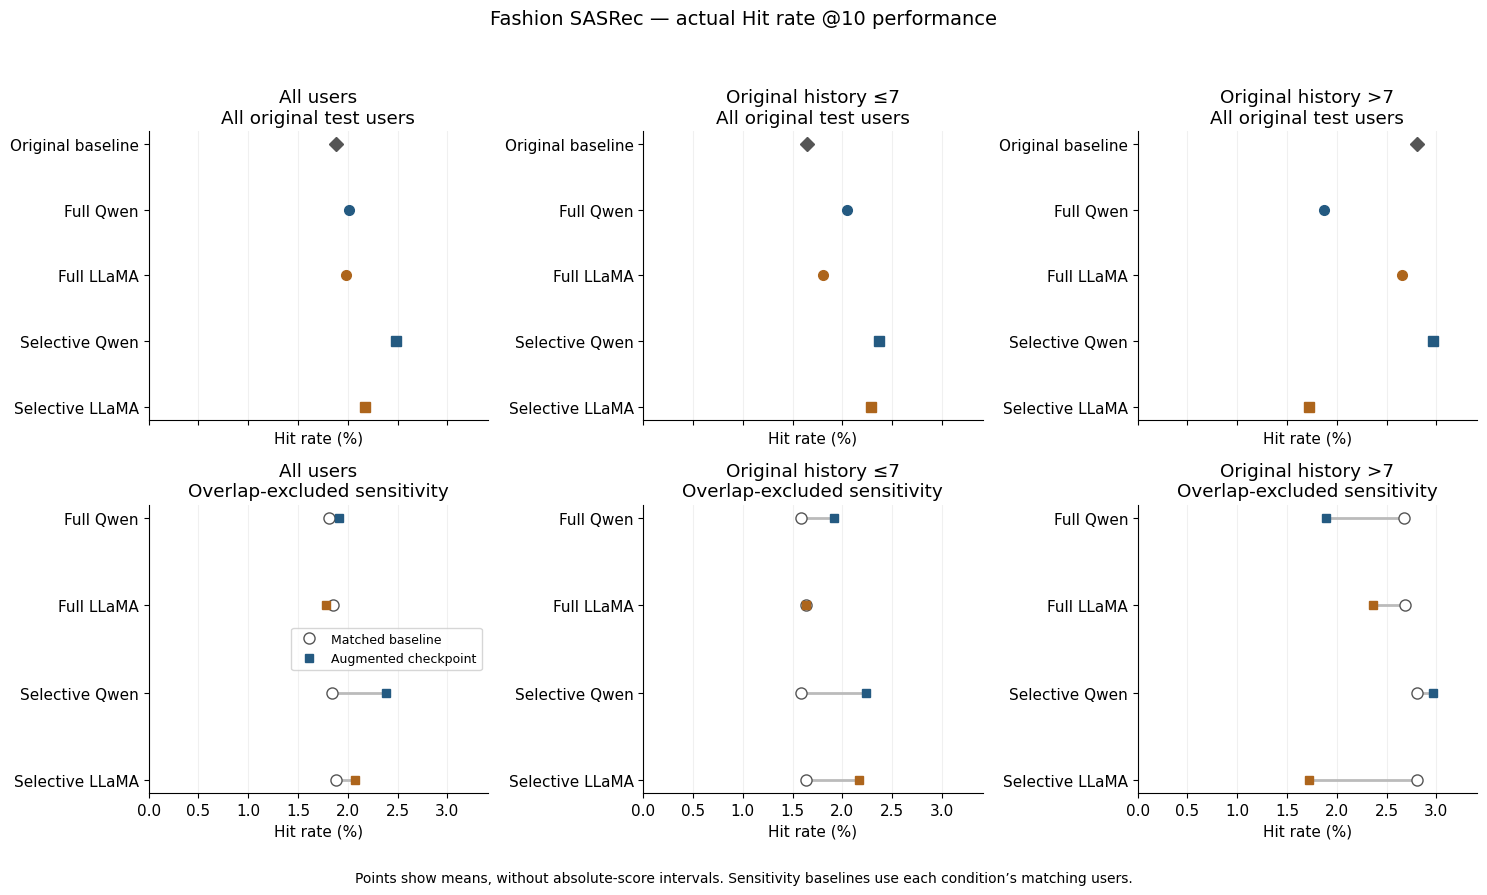

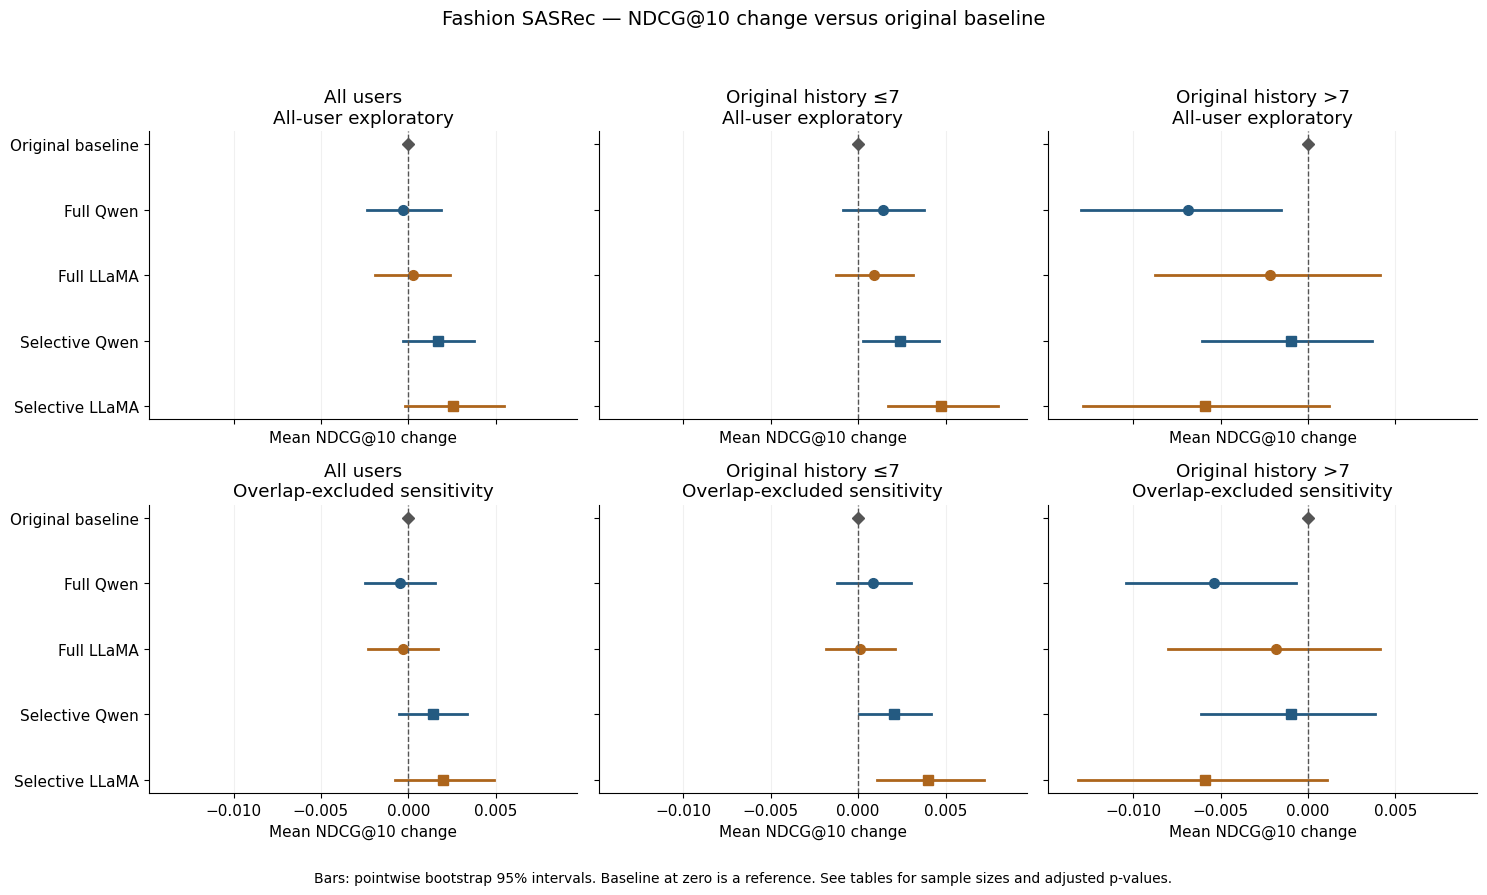

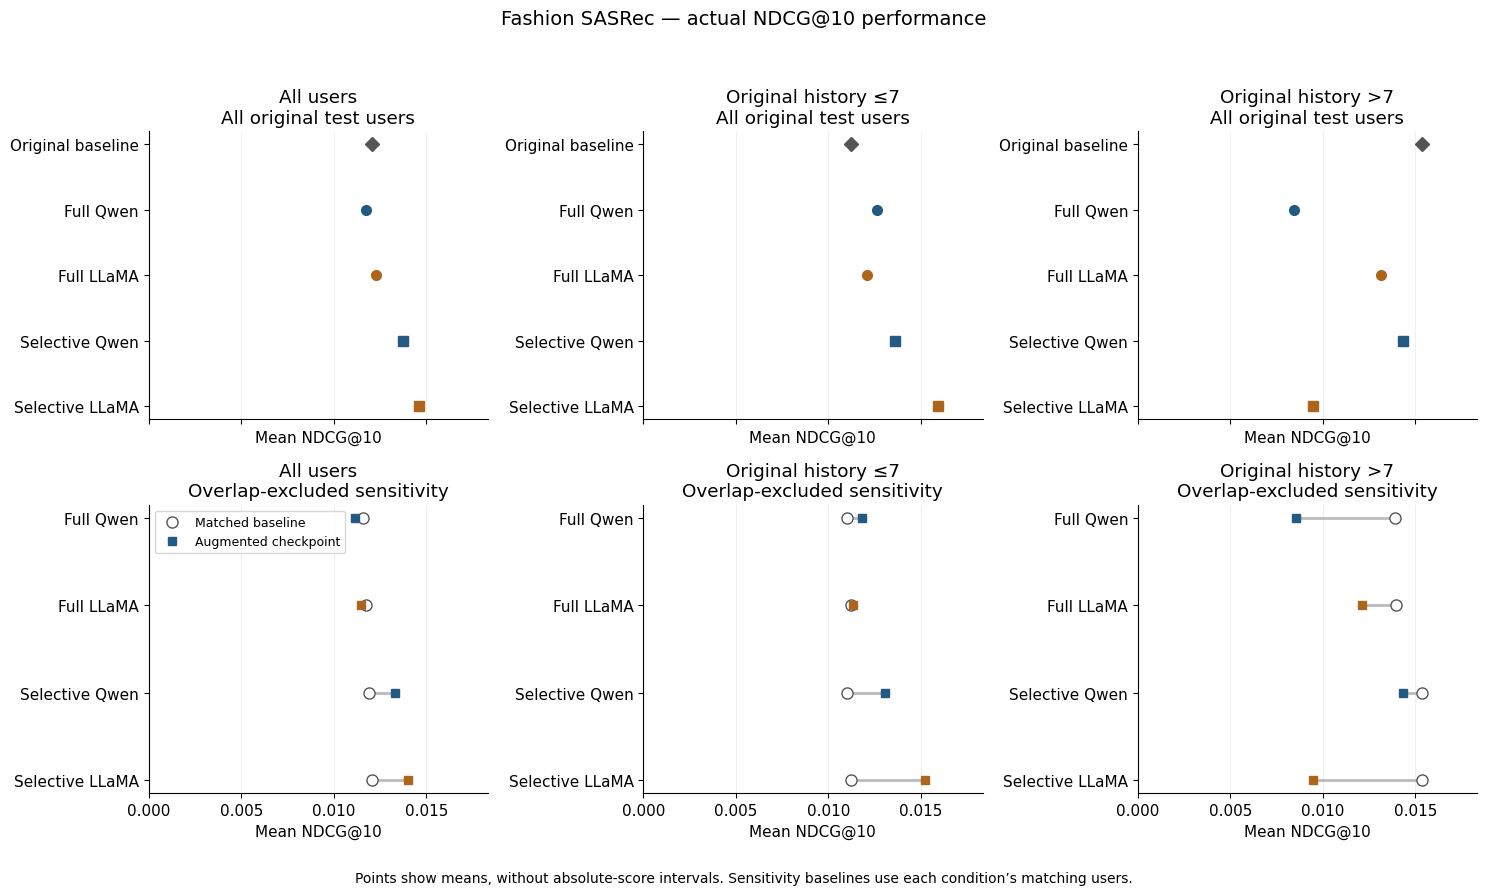

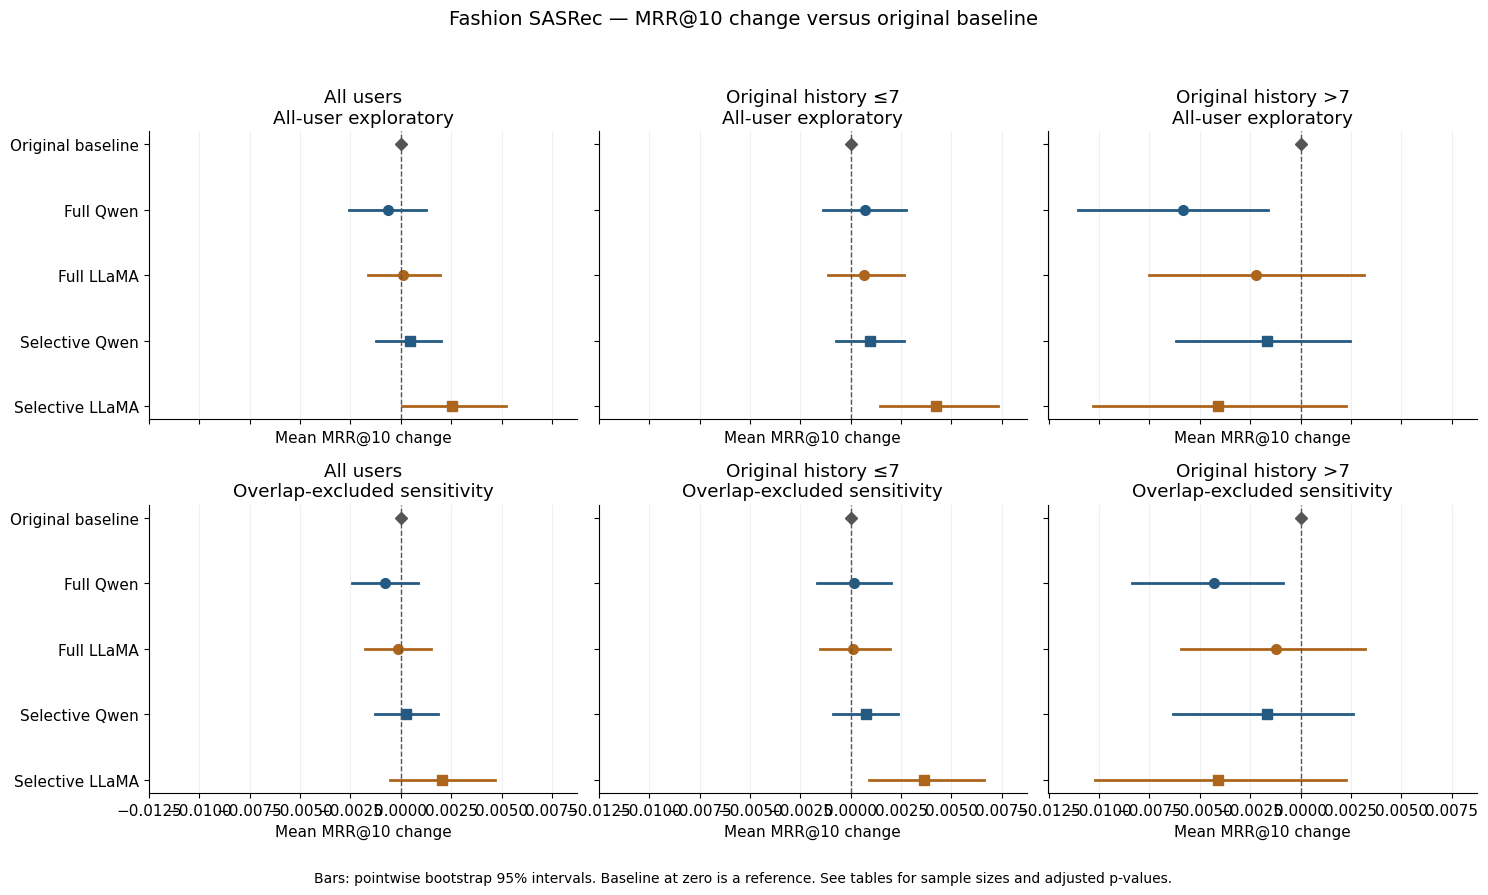

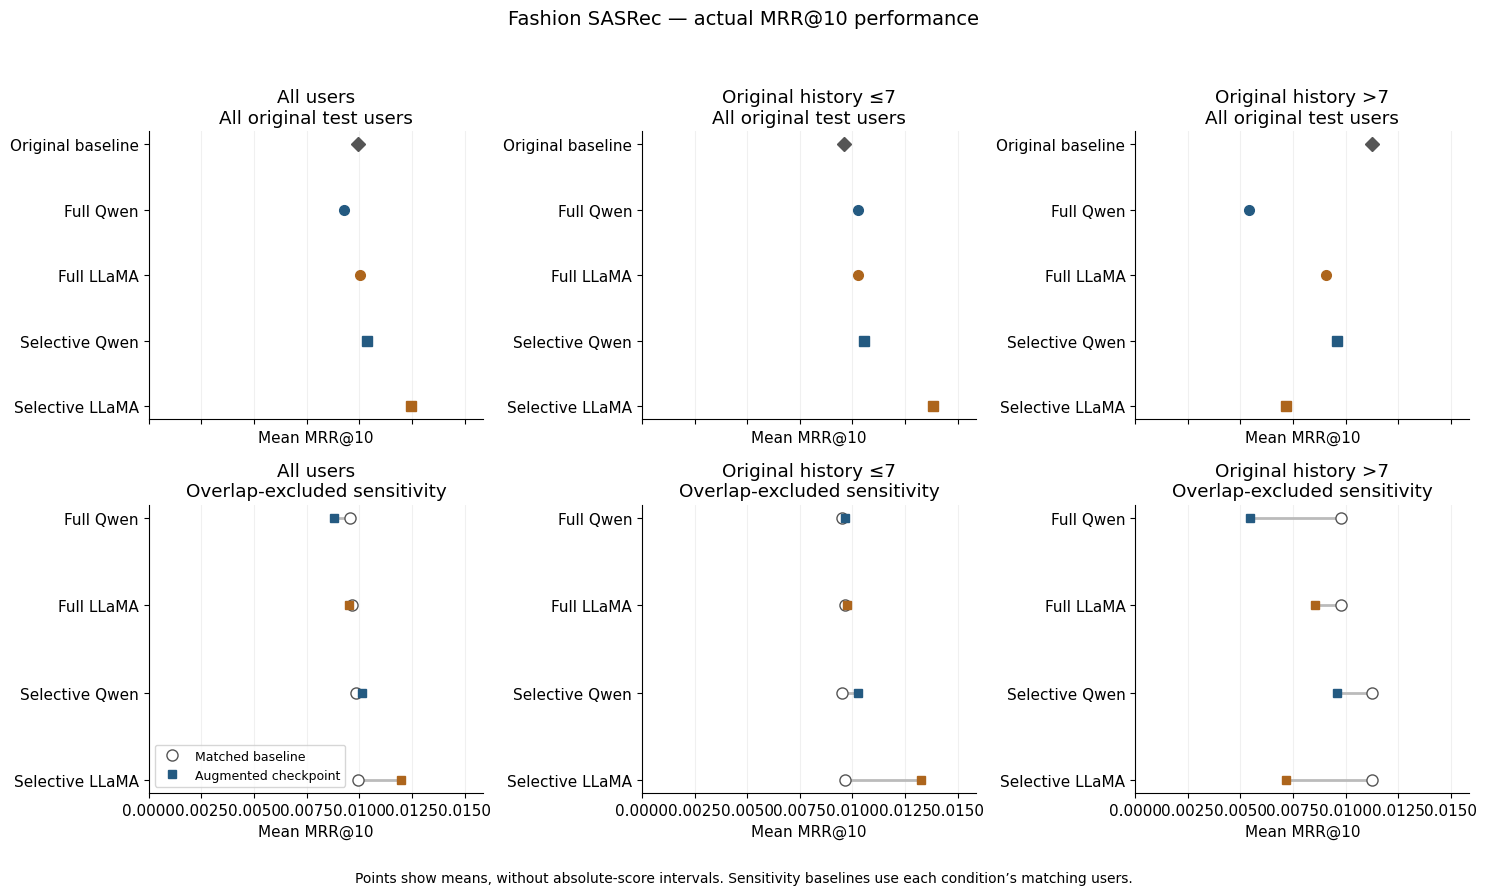

In [ ]:
COLORS = {'full_qwen': '#245A81', 'selective_qwen': '#245A81', 'full_llama': '#AD651C', 'selective_llama': '#AD651C'}
BASELINE_COLOR = '#555555'

def save_and_show(fig, filename):
    fig.savefig(RUN_DIR / 'figures' / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def plot_metric_results(result_table, absolute_table):
    for metric in DISPLAY_METRICS:
        selected = result_table.loc[result_table.metric.eq(metric)]
        scale = 100. if metric == 'hit@10' else 1.
        low, high = selected.ci95_low.min() * scale, selected.ci95_high.max() * scale
        span = max(high - low, .1 if metric == 'hit@10' else .001)
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
        for r, population in enumerate(POPULATIONS):
            for axis, group in zip(axes[r], GROUPS):
                rows = selected.loc[selected.population.eq(population) & selected.group.eq(group)].set_index('condition')
                axis.plot(0, 0, marker='D', color=BASELINE_COLOR, markersize=6)
                for y, condition in enumerate(CONDITIONS, start=1):
                    row = rows.loc[condition]
                    axis.plot([row.ci95_low * scale, row.ci95_high * scale], [y, y], color=COLORS[condition], linewidth=2)
                    axis.plot(row.delta * scale, y, marker='o' if condition.startswith('full') else 's', color=COLORS[condition], markersize=7)
                axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
                axis.set_xlim(min(low, 0) - .08 * span, max(high, 0) + .08 * span)
                axis.set_yticks(range(5), ['Original baseline'] + [LABELS[c] for c in CONDITIONS])
                axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
                axis.grid(axis='x', alpha=.18)
                axis.set_xlabel('Hit rate change (percentage points)' if metric == 'hit@10' else f'Mean {METRIC_TITLES[metric]} change')
        axes[0, 0].invert_yaxis()
        fig.suptitle('Fashion SASRec — ' + METRIC_TITLES[metric] + ' change versus original baseline', fontsize=14)
        fig.text(.5, .01, 'Bars: pointwise bootstrap 95% intervals. Baseline at zero is a reference. See tables for sample sizes and adjusted p-values.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_changes.png')

        # Main absolute values: five standalone rows. Sensitivity: matched pairs.
        max_value = max(absolute_table[metric].max(), selected[['baseline_mean', 'augmented_mean']].max().max()) * scale
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True)
        for axis, group in zip(axes[0], GROUPS):
            rows = absolute_table.loc[absolute_table.group.eq(group)].set_index('condition')
            for y, condition in enumerate(['baseline'] + CONDITIONS):
                axis.plot(rows.loc[condition, metric] * scale, y, marker='D' if condition == 'baseline' else ('o' if condition.startswith('full') else 's'),
                          color=BASELINE_COLOR if condition == 'baseline' else COLORS[condition], markersize=7)
            axis.set_yticks(range(5), [LABELS[c] for c in ['baseline'] + CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nAll original test users')
        for axis, group in zip(axes[1], GROUPS):
            rows = selected.loc[selected.population.eq('overlap_excluded_sensitivity') & selected.group.eq(group)].set_index('condition')
            for y, condition in enumerate(CONDITIONS):
                row = rows.loc[condition]
                axis.plot([row.baseline_mean * scale, row.augmented_mean * scale], [y, y], color='#BBBBBB', linewidth=2)
                axis.plot(row.baseline_mean * scale, y, marker='o', markerfacecolor='white', markeredgecolor=BASELINE_COLOR, markersize=8,
                          linestyle='none', label='Matched baseline' if y == 0 else None)
                axis.plot(row.augmented_mean * scale, y, marker='s', color=COLORS[condition], markersize=6,
                          linestyle='none', label='Augmented checkpoint' if y == 0 else None)
            axis.set_yticks(range(4), [LABELS[c] for c in CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nOverlap-excluded sensitivity')
        axes[1, 0].legend(loc='best', fontsize=9)
        for axis in axes.flat:
            axis.set_xlim(0, max(max_value * 1.15, .1 if metric == 'hit@10' else .001))
            axis.set_xlabel('Hit rate (%)' if metric == 'hit@10' else 'Mean ' + METRIC_TITLES[metric])
            axis.grid(axis='x', alpha=.18)
        fig.suptitle('Fashion SASRec — actual ' + METRIC_TITLES[metric] + ' performance', fontsize=14)
        fig.text(.5, .01, 'Points show means, without absolute-score intervals. Sensitivity baselines use each condition’s matching users.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_absolute_scores.png')

plot_metric_results(table, overview)

### 15. Hit gains/losses and sensitivity to overlaps
Hit-transition bars show the percentage of all users in each displayed cohort who gain or lose a hit; their denominators differ in sensitivity panels and appear in the transition table. The sparse-user sensitivity figure compares the two estimates and their pointwise intervals descriptively; it does not test whether excluding users caused a change. The audit chart counts each overlap user once, even if both validation and test items overlap.

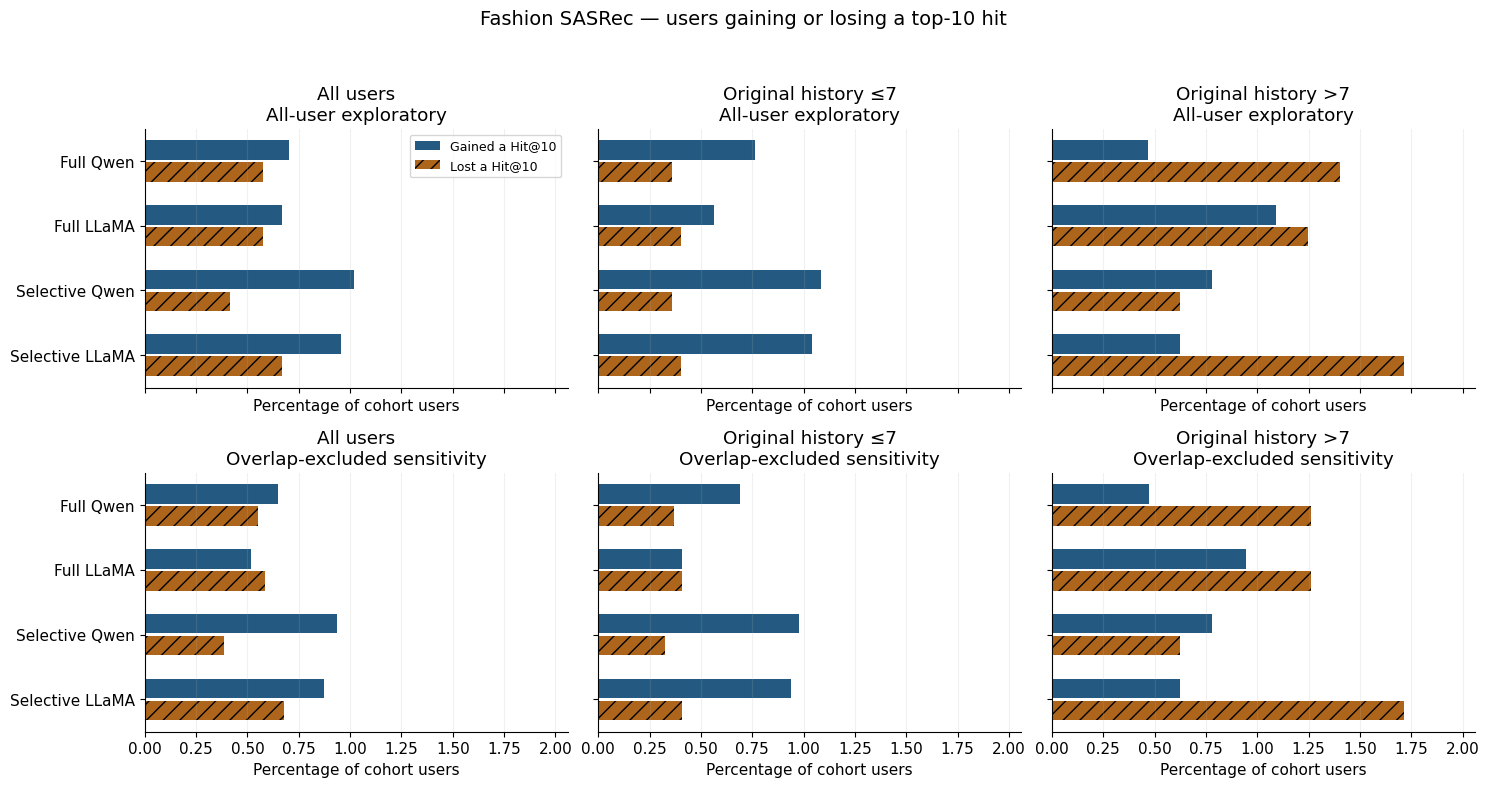

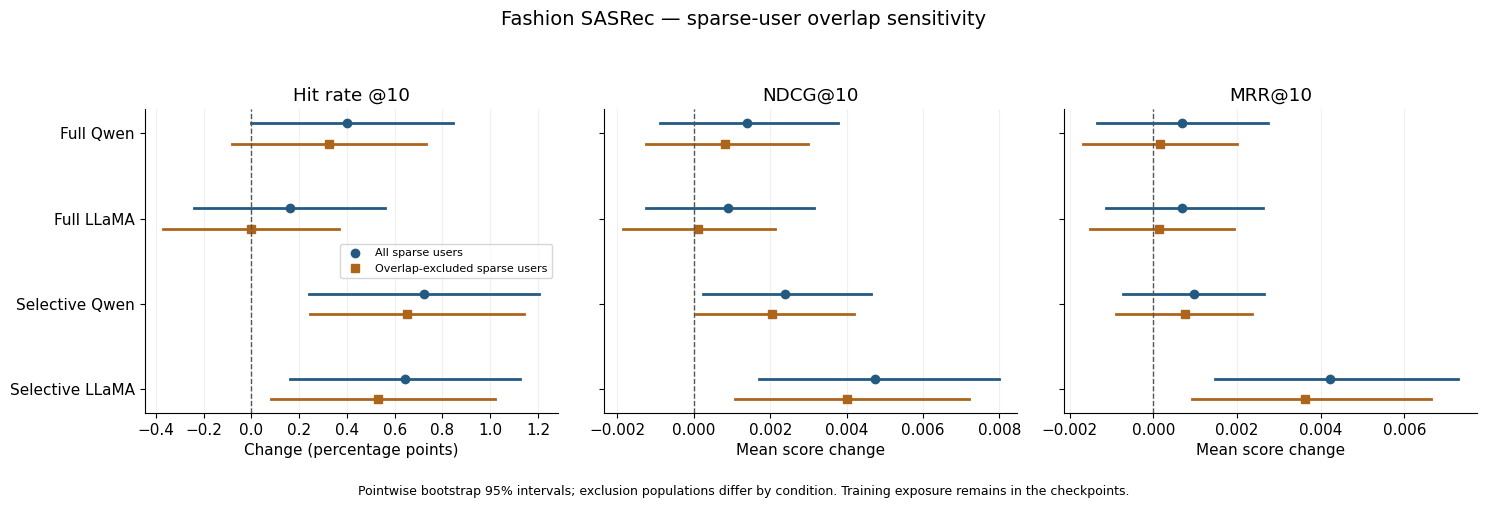

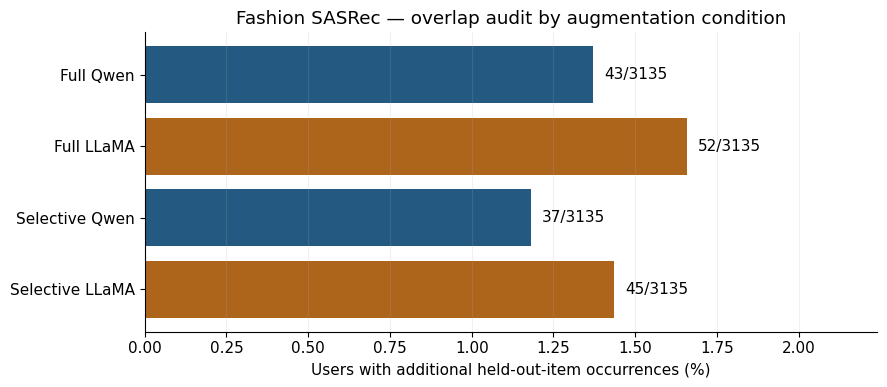

In [ ]:
# User-level Hit gains and losses.
limit = max(transitions[['gained_hit_pct', 'lost_hit_pct']].max().max() * 1.2, .1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for r, population in enumerate(POPULATIONS):
    for axis, group in zip(axes[r], GROUPS):
        rows = transitions.loc[transitions.population.eq(population) & transitions.group.eq(group)].set_index('condition').reindex(CONDITIONS)
        y = np.arange(len(CONDITIONS))
        axis.barh(y - .17, rows.gained_hit_pct, height=.3, color='#245A81', label='Gained a Hit@10')
        axis.barh(y + .17, rows.lost_hit_pct, height=.3, color='#AD651C', hatch='//', label='Lost a Hit@10')
        axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
        axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
        axis.set_xlim(0, limit)
        axis.set_xlabel('Percentage of cohort users')
        axis.grid(axis='x', alpha=.18)
axes[0, 0].invert_yaxis()
axes[0, 0].legend(loc='best', fontsize=9)
fig.suptitle('Fashion SASRec — users gaining or losing a top-10 hit', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
save_and_show(fig, 'hit_gains_and_losses.png')

# Side-by-side sensitivity estimates for sparse users, all three metrics.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for axis, metric in zip(axes, DISPLAY_METRICS):
    scale = 100. if metric == 'hit@10' else 1.
    for j, population in enumerate(POPULATIONS):
        rows = table.loc[table.metric.eq(metric) & table.group.eq('sparse') & table.population.eq(population)].set_index('condition')
        for y, condition in enumerate(CONDITIONS):
            row = rows.loc[condition]
            yy = y + (-.12 if j == 0 else .12)
            color = '#245A81' if j == 0 else '#AD651C'
            axis.plot([row.ci95_low * scale, row.ci95_high * scale], [yy, yy], color=color, linewidth=2)
            axis.plot(row.delta * scale, yy, marker='o' if j == 0 else 's', color=color, markersize=6,
                      linestyle='none', label=('All sparse users' if j == 0 else 'Overlap-excluded sparse users') if y == 0 else None)
    axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
    axis.set_title(METRIC_TITLES[metric])
    axis.set_xlabel('Change (percentage points)' if metric == 'hit@10' else 'Mean score change')
    axis.set_yticks(range(4), [LABELS[c] for c in CONDITIONS])
    axis.grid(axis='x', alpha=.18)
axes[0].invert_yaxis()
axes[0].legend(loc='best', fontsize=8)
fig.suptitle('Fashion SASRec — sparse-user overlap sensitivity', fontsize=14)
fig.text(.5, .01, 'Pointwise bootstrap 95% intervals; exclusion populations differ by condition. Training exposure remains in the checkpoints.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, .05, 1, .93])
save_and_show(fig, 'sparse_overlap_sensitivity_all_metrics.png')

fig, axis = plt.subplots(figsize=(9, 4))
ordered_audits = audits.set_index('condition').reindex(CONDITIONS)
y = np.arange(len(CONDITIONS))
axis.barh(y, ordered_audits.overlap_pct, color=[COLORS[c] for c in CONDITIONS])
axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
axis.invert_yaxis()
axis.set_xlabel('Users with additional held-out-item occurrences (%)')
axis.set_title('Fashion SASRec — overlap audit by augmentation condition')
maximum = max(float(ordered_audits.overlap_pct.max()), .1)
axis.set_xlim(0, maximum * 1.35)
for yy, row in enumerate(ordered_audits.itertuples()):
    axis.text(row.overlap_pct + .02 * maximum, yy, f'{row.any_overlap_users}/{row.users}', va='center')
axis.grid(axis='x', alpha=.18)
fig.tight_layout()
save_and_show(fig, 'holdout_overlap_audit.png')

## Checks and takeaways
### 12. Save the manifest and bounded interpretation
All results are exploratory analyses of existing checkpoints. The supplied notebook's selective comparisons already showed possible gains for sparse users but no corrected NDCG significance and no proof of no harm; do not carry those old p-values into the expanded family. This cell summarizes only newly computed results.

In [ ]:
environment = {p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']}
manifest = {'scope': 'Fashion SASRec baseline versus full/selective Qwen/LLaMA', 'threshold': THRESHOLD,
            'k': K, 'seed': SEED, 'bootstrap_resamples': BOOTSTRAP_RESAMPLES,
            'difference_tests_per_population': len(CONDITIONS) * 3 * len(METRICS),
            'policy_tests_per_population': 18, 'hit_mcnemar_tests_per_population': 12,
            'derived_metrics': {'recall@10': 'hit@10', 'precision@10': 'hit@10 / 10'},
            'no_harm_margins': NO_HARM_MARGINS, 'margin_justifications': MARGIN_JUSTIFICATIONS,
            'environment': environment, 'inputs': provenance,
            'limitations': ['Checkpoint-conditional inference; no repeated training seeds',
                           'Different training batch sizes', 'Synthetic holdout-item overlaps',
                           'Sensitivity exclusions do not undo model training exposure',
                           'Pointwise intervals; adjusted p-values govern multiple-test decisions']}
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
summary_lines = ['Fashion SASRec full/selective augmentation comparisons',
                 'Delta = augmented minus baseline. All conclusions refer to these checkpoints.',
                 'Holm correction: 36 planned difference tests per population.', '']
for row in table.to_dict('records'):
    p = row['p_holm']
    conclusion = ('statistically detected increase' if row['delta'] > 0 else 'statistically detected decrease') if pd.notna(p) and p < .05 else 'difference not established under Holm correction'
    summary_lines.append(f"{row['condition']} | {row['population']} | {row['group']} | {row['metric']} | n={row['users']} | delta={row['delta']:.6f} | {conclusion}")
summary_lines += ['', 'Nonsignificance does not establish equivalence or no meaningful harm.',
                  'Full longer-history users received augmentation; selective longer-history users did not.',
                  'Overlap-excluded sensitivity is not a contamination-free retraining experiment.']
(RUN_DIR / 'analysis/interpretation.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))
print('\nAll outputs:', RUN_DIR)

Fashion SASRec full/selective augmentation comparisons
Delta = augmented minus baseline. All conclusions refer to these checkpoints.
Holm correction: 36 planned difference tests per population.

full_qwen | all_users_exploratory | all | ndcg@10 | n=3135 | delta=-0.000289 | difference not established under Holm correction
full_qwen | all_users_exploratory | all | hit@10 | n=3135 | delta=0.001276 | difference not established under Holm correction
full_qwen | all_users_exploratory | all | mrr@10 | n=3135 | delta=-0.000644 | difference not established under Holm correction
full_qwen | all_users_exploratory | sparse | ndcg@10 | n=2494 | delta=0.001406 | difference not established under Holm correction
full_qwen | all_users_exploratory | sparse | hit@10 | n=2494 | delta=0.004010 | difference not established under Holm correction
full_qwen | all_users_exploratory | sparse | mrr@10 | n=2494 | delta=0.000689 | difference not established under Holm correction
full_qwen | all_users_exploratory | 

## Next steps
Share `analysis/absolute_performance.csv`, `analysis/group_results.csv`, `analysis/hit_transitions.csv`, `analysis/full_vs_selective.csv`, `analysis/cohort_effect_contrasts.csv` and `preparation/augmentation_audit.csv` for interpretation. Keep the new `run_manifest.json` and checkpoint-config audit with your results. To reuse this for another model/dataset, explicitly update checkpoint names, recorded results, expected augmentation policy and cohort rules; this notebook does not silently extend to BERT4Rec/GRU4Rec or Video Games.

For a controlled augmentation-only claim, use matched training settings and remove synthetic holdout-item overlaps before training. Existing-checkpoint sensitivity analyses cannot replace that experiment. Agree a meaningful no-harm margin with your supervisor before using the optional margin cell.